This is where i am importing all the library and the v2 of my breast cancer model

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    GridSearchCV, TunedThresholdClassifierCV,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif, chi2, f_classif
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    recall_score, f1_score, roc_auc_score, roc_curve,
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from ml_utils import MultiMethodFeatureSelector

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully")

All libraries imported successfully


Cell 2 - - Load & Explore Dataset

In [2]:
# Load dataset
# Using the already-encoded preprocessed dataset directly.
df = pd.read_csv('data/breast_cancer_preprocessed.csv')

print(f"Dataset loaded successfully")
print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")

print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df['cancer'].value_counts().to_dict())

print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully
Dataset shape: 1697 rows x 22 columns

Columns:
['age', 'menarche', 'menopause', 'agefirst', 'children', 'breastfeeding', 'nrelbc', 'biopsies', 'hyperplasia', 'race', 'year', 'imc', 'weight', 'exercise', 'alcohol', 'tobacco', 'allergies', 'emotional', 'depressive', 'histologicalclass', 'birads', 'cancer']

Target distribution:
{1: 1160, 0: 537}

Missing values:
age                  0
menarche             0
menopause            0
agefirst             0
children             0
breastfeeding        0
nrelbc               0
biopsies             0
hyperplasia          0
race                 0
year                 0
imc                  0
weight               0
exercise             0
alcohol              0
tobacco              0
allergies            0
emotional            0
depressive           0
histologicalclass    0
birads               0
cancer               0
dtype: int64


inspect raw data

In [3]:
# ==========================================
# INSPECT RAW VALUES
# ==========================================

print("\n" + "=" * 60)
print("RAW DATA INSPECTION")
print("=" * 60)

print("\nRace values:")
print(df['race'].value_counts(dropna=False))

print("\nAllergy values:")
print(df['allergies'].value_counts(dropna=False))

print("\nUnique race values:")
print(df['race'].unique())

print("\nUnique allergy values:")
print(df['allergies'].unique())


RAW DATA INSPECTION

Race values:
race
2    723
1    547
0    427
Name: count, dtype: int64

Allergy values:
allergies
1    963
0    734
Name: count, dtype: int64

Unique race values:
[2 1 0]

Unique allergy values:
[1 0]


Cell 3 - Drop Irrelevant & Imaging Columns

In [4]:
irr_cols = ['year', 'birads', 'histologicalclass', 'weight', 'imc']

leak_cols = ['biopsies', 'emotional', 'depressive']

df = df.drop(columns=irr_cols + leak_cols)

print(f"Dropped irrelevant/imaging columns: {irr_cols}")
print(f"Dropped leaky/post-diagnosis columns: {leak_cols}")
print(f"New dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Columns remaining: {df.columns.tolist()}")

Dropped irrelevant/imaging columns: ['year', 'birads', 'histologicalclass', 'weight', 'imc']
Dropped leaky/post-diagnosis columns: ['biopsies', 'emotional', 'depressive']
New dataset shape: 1697 rows x 14 columns
Columns remaining: ['age', 'menarche', 'menopause', 'agefirst', 'children', 'breastfeeding', 'nrelbc', 'hyperplasia', 'race', 'exercise', 'alcohol', 'tobacco', 'allergies', 'cancer']


inspect raw unique data

In [5]:
print("Raw race unique values:")
print(df['race'].unique())
print(df['race'].apply(type).value_counts())  # check for mixed types

print("\nRaw allergies unique values:")
print(df['allergies'].unique())

Raw race unique values:
[2 1 0]
race
<class 'int'>    1697
Name: count, dtype: int64

Raw allergies unique values:
[1 0]


Cell 4 --  target distribution

In [6]:
# NOTE: race and allergies are already encoded in breast_cancer_preprocessed.csv
# (race: Black=0, Mixed=1, White=2 | allergies: No/missing=0, any allergy=1).
# The re-mapping that used to live here was operating on already-numeric data
# and silently produced NaN/incorrect values, so it has been removed.
print("✅ No re-encoding needed — data already correctly encoded on load")

✅ No re-encoding needed — data already correctly encoded on load


Cell 5 - Train / Test Split

In [7]:
X = df.drop(columns=['cancer'])
y = df['cancer']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"split complete")
print(f" Train: {len(X_train)} samples, Test: {len(X_test)} samples")
print(f"Train cancer rate: {y_train.mean():.2%}, Test cancer rate: {y_test.mean():.2%}")
print()
print("Feature selection, scaling, and SMOTE now live INSIDE the pipeline,")
print("so they are refit per-CV-fold on training data only.")

split complete
 Train: 1357 samples, Test: 340 samples
Train cancer rate: 68.39%, Test cancer rate: 68.24%

Feature selection, scaling, and SMOTE now live INSIDE the pipeline,
so they are refit per-CV-fold on training data only.


Cell 6 - Custom Feature Selector (Pipeline-safe)

In [8]:
def build_pipeline(clf):
    """Selector -> SMOTE -> Classifier, all CV-safe."""
    return Pipeline([
        ('selector', MultiMethodFeatureSelector(k=10)),
        ('smote', SMOTE(random_state=42)),
        ('clf', clf),
    ])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("✅ Feature selector + pipeline factory ready")

✅ Feature selector + pipeline factory ready


Cell 7 - Logistic Regression (Pipeline + Threshold Tuning).

MODEL 1 — LOGISTIC REGRESSION

🔁 5-Fold CV ROC-AUC (pipeline): 0.9795 ± 0.0047
   Individual folds  : [np.float64(0.9807), np.float64(0.9877), np.float64(0.9744), np.float64(0.9786), np.float64(0.976)]

📌 Top 10 Selected Features:
1. tobacco
2. alcohol
3. hyperplasia
4. breastfeeding
5. children
6. age
7. nrelbc
8. menopause
9. agefirst
10. menarche

🎯 Tuned decision threshold : 0.3232  (default is 0.5000)

📊 LR — Test Performance:
   Accuracy             : 0.9265
   Recall (Sensitivity) : 0.9871  ← CRITICAL FOR CANCER SCREENING
   F1-Score             : 0.9482
   ROC-AUC              : 0.9647

   Classification Report:
              precision    recall  f1-score   support

   No Cancer       0.97      0.80      0.87       108
      Cancer       0.91      0.99      0.95       232

    accuracy                           0.93       340
   macro avg       0.94      0.89      0.91       340
weighted avg       0.93      0.93      0.92       340



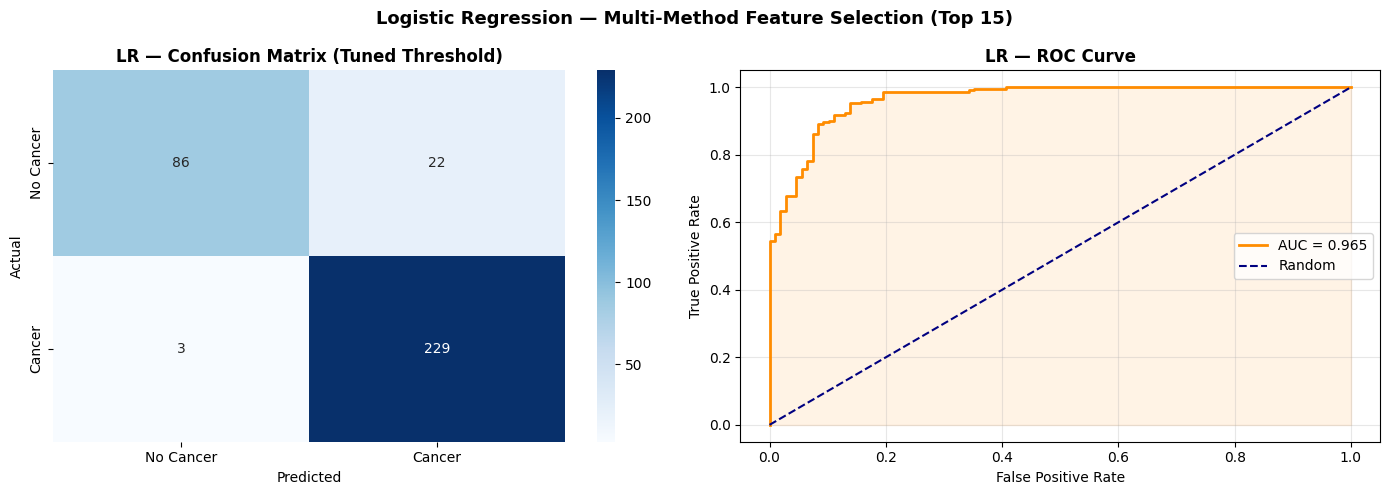

LR complete


In [9]:
print("=" * 60)
print("MODEL 1 — LOGISTIC REGRESSION")
print("=" * 60)

lr_pipeline = build_pipeline(LogisticRegression(max_iter=1000, random_state=42))

cv_lr = cross_val_score(lr_pipeline, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"\n🔁 5-Fold CV ROC-AUC (pipeline): {cv_lr.mean():.4f} ± {cv_lr.std():.4f}")
print(f"   Individual folds  : {[round(s, 4) for s in cv_lr]}")

lr_tuned = TunedThresholdClassifierCV(
    lr_pipeline, scoring='f1', cv=cv, store_cv_results=True,
)
lr_tuned.fit(X_train, y_train)

lr_pipeline.fit(X_train, y_train)
selector = lr_pipeline.named_steps['selector']

print("\n📌 Top 10 Selected Features:")
for i, feature in enumerate(selector.top_features_, start=1):
    print(f"{i}. {feature}")

print(f"\n🎯 Tuned decision threshold : {lr_tuned.best_threshold_:.4f}  (default is 0.5000)")

y_pred_lr = lr_tuned.predict(X_test)
y_prob_lr = lr_tuned.predict_proba(X_test)[:, 1]

acc_lr = accuracy_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print(f"\n📊 LR — Test Performance:")
print(f"   Accuracy             : {acc_lr:.4f}")
print(f"   Recall (Sensitivity) : {rec_lr:.4f}  ← CRITICAL FOR CANCER SCREENING")
print(f"   F1-Score             : {f1_lr:.4f}")
print(f"   ROC-AUC              : {roc_auc_lr:.4f}")
print(f"\n   Classification Report:")
print(classification_report(y_test, y_pred_lr, target_names=['No Cancer', 'Cancer']))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues',
            ax=axes[0], xticklabels=['No Cancer', 'Cancer'], yticklabels=['No Cancer', 'Cancer'])
axes[0].set_title('LR — Confusion Matrix (Tuned Threshold)', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
axes[1].plot(fpr_lr, tpr_lr, color='darkorange', lw=2, label=f'AUC = {roc_auc_lr:.3f}')
axes[1].plot([0, 1], [0, 1], 'navy', lw=1.5, linestyle='--', label='Random')
axes[1].fill_between(fpr_lr, tpr_lr, alpha=0.1, color='darkorange')
axes[1].set_title('LR — ROC Curve', fontweight='bold')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle(
    'Logistic Regression — Multi-Method Feature Selection (Top 15)',
    fontsize=13,
    fontweight='bold'
)
plt.tight_layout()
plt.savefig('breast_lr_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("LR complete")

Cell - 8 KNN (GridSearchCV for K + Threshold Tuning)

MODEL 2 — K-NEAREST NEIGHBORS (KNN)

🔍 Finding optimal K via GridSearchCV (scoring = F1)...
   ✅ Best K : 7  (CV Recall : 0.9434)
   5-Fold CV ROC-AUC : 0.9611 ± 0.0055
   Individual folds  : [np.float64(0.956), np.float64(0.9711), np.float64(0.9617), np.float64(0.956), np.float64(0.9609)]

🎯 Tuned decision threshold : 0.6465  (default is 0.5000)

📊 KNN — Test Performance:
   Accuracy             : 0.9118
   Recall (Sensitivity) : 0.9267  ← CRITICAL FOR CANCER SCREENING
   F1-Score             : 0.9348
   ROC-AUC              : 0.9317

   Classification Report:
              precision    recall  f1-score   support

   No Cancer       0.85      0.88      0.86       108
      Cancer       0.94      0.93      0.93       232

    accuracy                           0.91       340
   macro avg       0.90      0.90      0.90       340
weighted avg       0.91      0.91      0.91       340



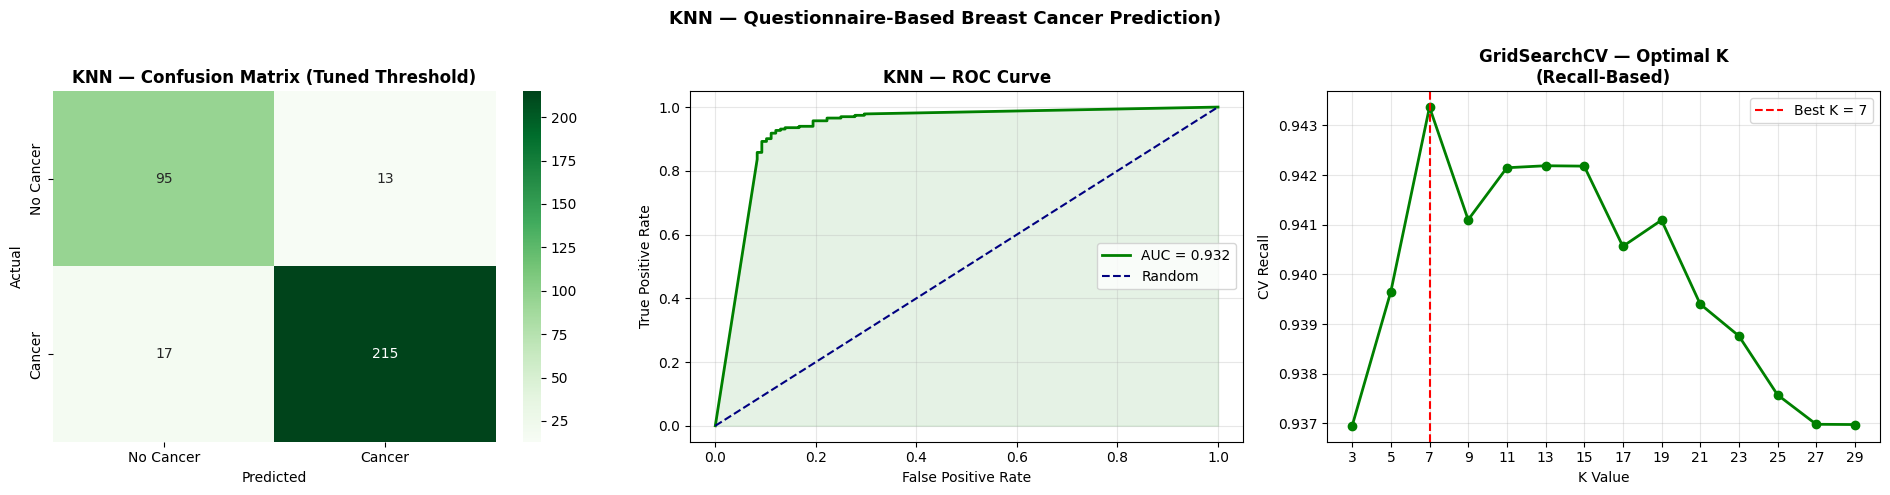

✅ KNN complete


In [10]:
print("=" * 60)
print("MODEL 2 — K-NEAREST NEIGHBORS (KNN)")
print("=" * 60)

knn_pipeline = build_pipeline(KNeighborsClassifier(weights='distance'))
param_grid_knn = {'clf__n_neighbors': list(range(3, 31, 2))}  # odd numbers from 3 to 29

print("\n🔍 Finding optimal K via GridSearchCV (scoring = F1)...")
knn_grid = GridSearchCV(knn_pipeline, param_grid_knn, scoring='f1', cv=cv, n_jobs=-1)
knn_grid.fit(X_train, y_train)

best_k = knn_grid.best_params_['clf__n_neighbors']
print(f"   ✅ Best K : {best_k}  (CV Recall : {knn_grid.best_score_:.4f})")

cv_knn = cross_val_score(knn_grid.best_estimator_, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"   5-Fold CV ROC-AUC : {cv_knn.mean():.4f} ± {cv_knn.std():.4f}")
print(f"   Individual folds  : {[round(s, 4) for s in cv_knn]}")

knn_tuned = TunedThresholdClassifierCV(
    knn_grid.best_estimator_, scoring='balanced_accuracy', cv=cv, store_cv_results=True,
)
knn_tuned.fit(X_train, y_train)
print(f"\n🎯 Tuned decision threshold : {knn_tuned.best_threshold_:.4f}  (default is 0.5000)")

y_pred_knn = knn_tuned.predict(X_test)
y_prob_knn = knn_tuned.predict_proba(X_test)[:, 1]

acc_knn = accuracy_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
roc_auc_knn = roc_auc_score(y_test, y_prob_knn)

print(f"\n📊 KNN — Test Performance:")
print(f"   Accuracy             : {acc_knn:.4f}")
print(f"   Recall (Sensitivity) : {rec_knn:.4f}  ← CRITICAL FOR CANCER SCREENING")
print(f"   F1-Score             : {f1_knn:.4f}")
print(f"   ROC-AUC              : {roc_auc_knn:.4f}")
print(f"\n   Classification Report:")
print(classification_report(y_test, y_pred_knn, target_names=['No Cancer', 'Cancer']))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Greens',
            ax=axes[0], xticklabels=['No Cancer', 'Cancer'], yticklabels=['No Cancer', 'Cancer'])
axes[0].set_title('KNN — Confusion Matrix (Tuned Threshold)', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
axes[1].plot(fpr_knn, tpr_knn, color='green', lw=2, label=f'AUC = {roc_auc_knn:.3f}')
axes[1].plot([0, 1], [0, 1], 'navy', lw=1.5, linestyle='--', label='Random')
axes[1].fill_between(fpr_knn, tpr_knn, alpha=0.1, color='green')
axes[1].set_title('KNN — ROC Curve', fontweight='bold')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].legend(); axes[1].grid(alpha=0.3)

k_range = param_grid_knn['clf__n_neighbors']
knn_cv_results = knn_grid.cv_results_['mean_test_score']
axes[2].plot(k_range, knn_cv_results, marker='o', color='green', lw=2)
axes[2].axvline(best_k, color='red', linestyle='--', label=f'Best K = {best_k}')
axes[2].set_title('GridSearchCV — Optimal K\n(Recall-Based)', fontweight='bold')
axes[2].set_xlabel('K Value'); axes[2].set_ylabel('CV Recall')
axes[2].set_xticks(k_range); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.suptitle('KNN — Questionnaire-Based Breast Cancer Prediction)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('breast_knn_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ KNN complete")

Cell 9 - SVM (GridSearchCV for C + Threshold Tuning)

MODEL 3 — SUPPORT VECTOR MACHINE (SVM)

🔍 Finding optimal C via GridSearchCV (scoring = F1)...
   C = 0.1   → CV Recall : 0.9385
   C = 0.5   → CV Recall : 0.9469
   C = 1.0   → CV Recall : 0.9461
   C = 5.0   → CV Recall : 0.9424
   C = 10.0  → CV Recall : 0.9414

   ✅ Best C : 0.5  (CV Recall : 0.9469)
   5-Fold CV ROC-AUC : 0.9786 ± 0.0039
   Individual folds  : [np.float64(0.9776), np.float64(0.9858), np.float64(0.9745), np.float64(0.9792), np.float64(0.9758)]

🎯 Tuned decision threshold : 0.7677  (default is 0.5000)

📊 SVM — Test Performance:
   Accuracy             : 0.9029
   Recall (Sensitivity) : 0.9095  ← CRITICAL FOR CANCER SCREENING
   F1-Score             : 0.9275
   ROC-AUC              : 0.9531

   Classification Report:
              precision    recall  f1-score   support

   No Cancer       0.82      0.89      0.85       108
      Cancer       0.95      0.91      0.93       232

    accuracy                           0.90       340
   macro avg       0.88      0.90   

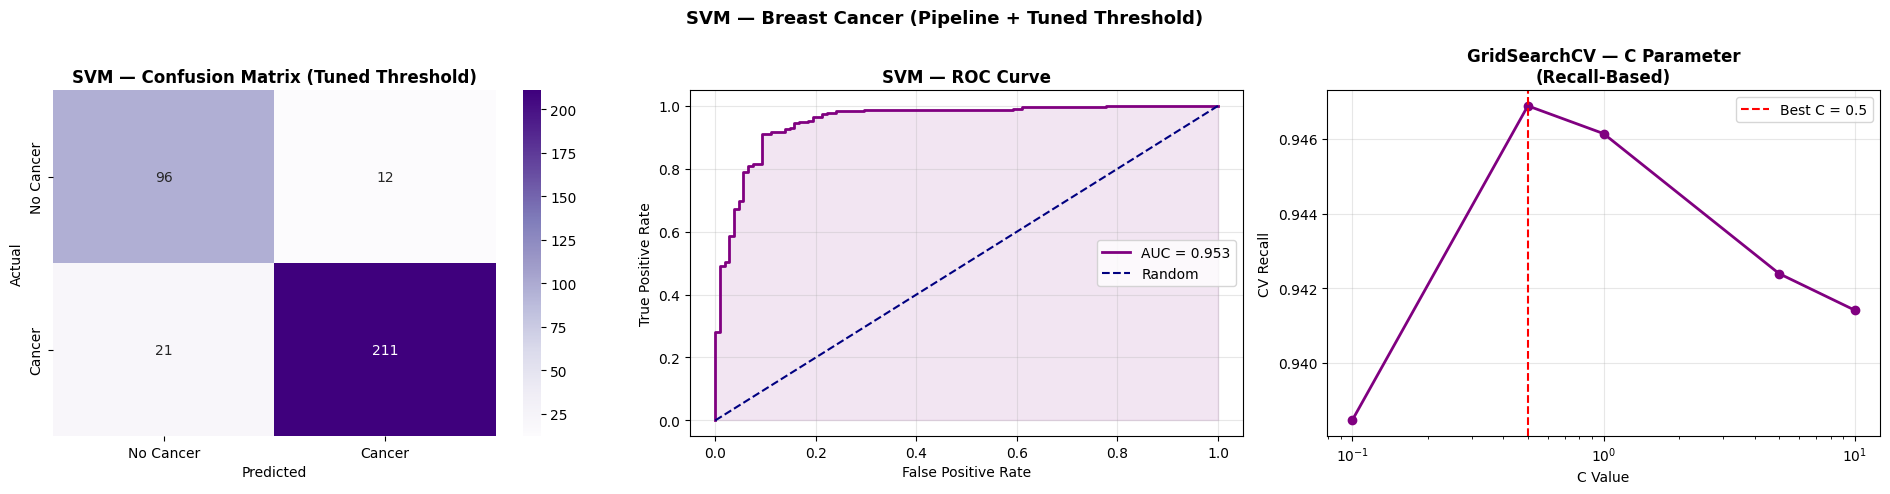

✅ SVM complete


In [11]:
print("=" * 60)
print("MODEL 3 — SUPPORT VECTOR MACHINE (SVM)")
print("=" * 60)

svm_pipeline = build_pipeline(SVC(kernel='rbf', gamma='scale', probability=True, random_state=42))
param_grid_svm = {'clf__C': [0.1, 0.5, 1.0, 5.0, 10.0]}

print("\n🔍 Finding optimal C via GridSearchCV (scoring = F1)...")
svm_grid = GridSearchCV(svm_pipeline, param_grid_svm, scoring='f1', cv=cv, n_jobs=-1)
svm_grid.fit(X_train, y_train)

for c, score in zip(param_grid_svm['clf__C'], svm_grid.cv_results_['mean_test_score']):
    print(f"   C = {c:<5} → CV Recall : {score:.4f}")

best_c = svm_grid.best_params_['clf__C']
print(f"\n   ✅ Best C : {best_c}  (CV Recall : {svm_grid.best_score_:.4f})")

cv_svm = cross_val_score(svm_grid.best_estimator_, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"   5-Fold CV ROC-AUC : {cv_svm.mean():.4f} ± {cv_svm.std():.4f}")
print(f"   Individual folds  : {[round(s, 4) for s in cv_svm]}")

svm_tuned = TunedThresholdClassifierCV(
    svm_grid.best_estimator_, scoring='balanced_accuracy', cv=cv, store_cv_results=True,
)
svm_tuned.fit(X_train, y_train)
print(f"\n🎯 Tuned decision threshold : {svm_tuned.best_threshold_:.4f}  (default is 0.5000)")

y_pred_svm = svm_tuned.predict(X_test)
y_prob_svm = svm_tuned.predict_proba(X_test)[:, 1]

acc_svm = accuracy_score(y_test, y_pred_svm)
rec_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
roc_auc_svm = roc_auc_score(y_test, y_prob_svm)

print(f"\n📊 SVM — Test Performance:")
print(f"   Accuracy             : {acc_svm:.4f}")
print(f"   Recall (Sensitivity) : {rec_svm:.4f}  ← CRITICAL FOR CANCER SCREENING")
print(f"   F1-Score             : {f1_svm:.4f}")
print(f"   ROC-AUC              : {roc_auc_svm:.4f}")
print(f"\n   Classification Report:")
print(classification_report(y_test, y_pred_svm, target_names=['No Cancer', 'Cancer']))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Purples',
            ax=axes[0], xticklabels=['No Cancer', 'Cancer'], yticklabels=['No Cancer', 'Cancer'])
axes[0].set_title('SVM — Confusion Matrix (Tuned Threshold)', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
axes[1].plot(fpr_svm, tpr_svm, color='purple', lw=2, label=f'AUC = {roc_auc_svm:.3f}')
axes[1].plot([0, 1], [0, 1], 'navy', lw=1.5, linestyle='--', label='Random')
axes[1].fill_between(fpr_svm, tpr_svm, alpha=0.1, color='purple')
axes[1].set_title('SVM — ROC Curve', fontweight='bold')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].legend(); axes[1].grid(alpha=0.3)

c_values = param_grid_svm['clf__C']
svm_cv_results = svm_grid.cv_results_['mean_test_score']
axes[2].plot(c_values, svm_cv_results, marker='o', color='purple', lw=2)
axes[2].axvline(best_c, color='red', linestyle='--', label=f'Best C = {best_c}')
axes[2].set_title('GridSearchCV — C Parameter\n(Recall-Based)', fontweight='bold')
axes[2].set_xlabel('C Value'); axes[2].set_ylabel('CV Recall')
axes[2].set_xscale('log'); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.suptitle('SVM — Breast Cancer (Pipeline + Tuned Threshold)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('breast_svm_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ SVM complete")

import joblib


In [19]:
import os, joblib
save_path = 'models/breast_cancer_lr_model.pkl'
os.makedirs('models', exist_ok=True)
joblib.dump(lr_tuned, save_path)
print("✅ Breast model saved to:", os.path.abspath(save_path))

✅ Breast model saved to: c:\Users\user\Desktop\cancer_prediction_model_v2\models\breast_cancer_lr_model.pkl
